# Review of AT2017gfo spectra: catalog JSON vs published data vs current inputs

**Read-only review.** Nothing here writes to `Inputs/`. The goal is to list every AT2017gfo spectrum we could add, check the copies in the compiled catalog `GW170817.json` (Open Kilonova Catalog format) against the published versions we already have, and flag problems before anything goes into the pipeline.

Current pipeline inputs: 10 Magellan spectra (Shappee+2017) and 29 ENGRAVE X-shooter arm spectra (+1.43 to +10.40 d).

Sections:
1. Inventory of the 50 spectra in the JSON
2. Magellan LDSS3/MagE: JSON vs our input files
3. X-shooter: JSON reductions (Pian, Smartt) vs ENGRAVE v1.0
4. Dereddened copies in the JSON
5. Duplicate data with different flux scales
6. Frame and telluric test (O$_2$ A band) for every spectrum
7. The new spectra, compared with ENGRAVE at the nearest epoch
8. Literature: published spectra not in the JSON
9. Summary

In [1]:
import pipeline_config as pconf
pconf.ensure_helper_paths()

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import spec_inventory as si

%matplotlib inline
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.width", 250)
pd.set_option("display.max_rows", 80)

SN = "AT2017gfo"
# The compiled catalog: set JSON_PATH directly, or it is looked for in the
# folders above the repository (it lives next to kn-sed-pipeline/).
JSON_PATH = None
if JSON_PATH is None:
    d = os.path.abspath(pconf.COCO_PATH)
    while JSON_PATH is None and d != os.path.dirname(d):
        d = os.path.dirname(d)
        if os.path.isfile(os.path.join(d, "GW170817.json")):
            JSON_PATH = os.path.join(d, "GW170817.json")
T0 = pconf.SN_EXPLOSION_MJD[SN]
Z = pconf.SN_REDSHIFT[SN]
EBV_MW = 0.1053                                                       # Inputs/SNe_Info/info.dat
RAW = os.path.join(pconf.spectroscopy_root(), "1_spec_original", SN)

ev, src = si.load_catalog(JSON_PATH)
print(len(ev["spectra"]), "spectra in", os.path.normpath(JSON_PATH))

50 spectra in /Users/ravkaur/Desktop/research/kilonova-SED/GW170817.json


## 1. Inventory

One row per spectrum in the JSON. `mjd_json` is the catalog MJD, which is **rounded to the day** for many entries (e.g. Pian's X-shooter, Kasliwal's Gemini): those times can be up to ~1 d early, so `mjd_probable` uses the night in the file name where it differs, and `phase_d` is computed from it. `frame` is the O$_2$ test of section 6. No spectrum in the JSON carries flux errors.

In [2]:
inv = si.inventory(ev, src, Z)

# probable observation time where the catalog time is rounded and the file name has the date
def probable_mjd(row):
    f = row.filename
    if f.startswith("XSGW08"):                 # Pian X-shooter: night of Aug DD, ~23:20 UT
        return 57983.95 + (int(f[6:8]) - 18)
    if "combinedarms" in f:                    # Smartt X-shooter, night of 2017-08-DD
        return 57983.97 + (int(f.split("_")[2][6:8]) - 18)
    if f.startswith("SSS17a_GS"):              # Pian GMOS "2.5d"
        return T0 + 2.5
    if f.startswith("fors2_unfluxcalib_4.5d"):
        return T0 + 4.5
    return row.mjd_json
inv.insert(2, "mjd_probable", inv.apply(probable_mjd, axis=1).round(3))
inv.insert(3, "phase_d", (inv.mjd_probable - T0).round(2))

# status relative to the current inputs (filled in by sections 2-5)
local = sorted(os.listdir(RAW))
def status(row):
    f = row.filename
    if row.instrument == "LDSS3":
        return "IN USE (identical to local file)"
    if "_dred" in f:
        return "dereddened copy of a Smartt X-shooter spectrum (do not use)"
    if "hooter" in row.instrument.lower():
        return "same X-shooter observation as ENGRAVE (other reduction)"
    if f.startswith("SSS17a_GS"):
        return "same data as Kasliwal GMOS 20170820 (x0.316 flux)"
    if "unfluxcalib" in f:
        return "NEW (NOT flux calibrated)"
    return "NEW"
inv.insert(4, "status", inv.apply(status, axis=1))
inv[["idx", "mjd_json", "mjd_probable", "phase_d", "status", "instrument", "paper", "filename",
     "wl_min", "wl_max", "pix_A", "frame"]]

,idx,mjd_json,mjd_probable,phase_d,status,instrument,paper,filename,wl_min,wl_max,pix_A,frame
0,0,57983.000000,57983.950,1.42,same X-shooter observation as ENGRAVE (other reduction),VLT-UT2 - X-Shooter,"Pian+2017 (Nature 551, 67); WISeREP",XSGW0818_smooth.dat,3501.532980,24786.429830,0.600000,no clear O2 signal (corrected?)
1,1,57983.018250,57983.018,0.49,IN USE (identical to local file),LDSS3,"Shappee+2017 (Science 358, 1574)",SSS17a-LDSS3-20170817_cal.flm,3725.600000,10101.200000,2.000000,rest frame (O2 dip at λ/(1+z))
2,2,57983.027880,57983.028,0.50,IN USE (identical to local file),LDSS3,"Shappee+2017 (Science 358, 1574)",SSS17a-LDSS3b-20170817_cal.flm,3730.700000,6454.100000,0.700000,no O2 coverage
3,3,57983.036200,57983.036,0.51,IN USE (identical to local file),LDSS3,"Shappee+2017 (Science 358, 1574)",SSS17a-LDSS3r-20170817_cal.flm,6386.700000,9901.400000,1.200000,rest frame (O2 dip at λ/(1+z))
4,4,57983.059980,57983.060,0.53,IN USE (identical to local file),LDSS3,"Shappee+2017 (Science 358, 1574)",SSS17a-MagE-20170817_cal.flm,3615.000000,6932.400000,0.300000,no clear O2 signal (corrected?) (B band only)
5,5,57983.971662,57983.972,1.44,NEW,EFOSC2,"Smartt+2017 (Nature 551, 75)",AT2017gfo_EFOSC2_20170818_photcal.dat,3332.110596,9973.590820,4.074528,no clear O2 signal (corrected?)
6,6,57983.974058,57983.974,1.45,NEW,Goodman Spectro,"Nicholl+2017 (ApJL 848, L18)",sss17a_20170818_tel.fits,4000.000000,8034.750977,1.979760,"observed, telluric residuals"
7,7,57983.991400,57983.991,1.46,IN USE (identical to local file),LDSS3,"Shappee+2017 (Science 358, 1574)",SSS17a-LDSS3-20170818_cal.flm,3785.200000,9119.300000,2.000000,rest frame (O2 dip at λ/(1+z))
8,8,57984.000000,57984.970,2.44,dereddened copy of a Smartt X-shooter spectrum (do not use),VLT-UT2 - X-Shooter,"Smartt+2017 (Nature 551, 75); WISeREP",AT2017gfo_XSH_20170819_combinedarms_photcal_dred.dat,3700.100000,22793.500000,0.600000,no clear O2 signal (corrected?)
9,9,57984.000000,57984.970,2.44,dereddened copy of a Smartt X-shooter spectrum (do not use),VLT-UT2 - X-Shooter,"Smartt+2017 (Nature 551, 75); WISeREP",AT2017gfo_XSH_20170819_combinedarms_photcal_dred_3Angs.dat,3701.600000,22793.600000,3.000000,no clear O2 signal (corrected?)


In [3]:
inv.groupby("status").size().rename("n spectra").to_frame()

,n spectra
status,
IN USE (identical to local file),10
NEW,23
NEW (NOT flux calibrated),2
dereddened copy of a Smartt X-shooter spectrum (do not use),4
same X-shooter observation as ENGRAVE (other reduction),10
same data as Kasliwal GMOS 20170820 (x0.316 flux),1


## 2. Magellan LDSS3 / MagE (Shappee+2017): JSON vs our input files

Our 10 "LDSS3" input files are **byte-for-byte the JSON spectra** (same pixels, same flux): they came from this catalog. Two of them are really **MagE** echelle spectra (`SSS17a-MagE-*`), not LDSS3. Their wavelengths are in the **rest frame** (O$_2$ A band at 7594/(1+z), section 6), which is why `REST_FRAME_FILES` shifts them in notebook 0.2. The only Shappee spectrum we do not use is the **IMACS** spectrum at 57985.018.

In [4]:
rows = []
for _, r in inv[inv.paper.str.startswith("Shappee")].iterrows():
    w, f = si.spectrum_array(ev["spectra"][r.idx])
    match = [x for x in local if x.startswith(("%.5f" % r.mjd_json).rstrip("0"))]
    if match:
        d = si.read_local(os.path.join(RAW, match[0]))
        same = si.identical(w, f, d[:, 0], d[:, 1])
    rows.append(dict(idx=r.idx, mjd=r.mjd_json, json_file=r.filename,
                     local_file=match[0] if match else "-", identical=same if match else None))
pd.DataFrame(rows)

,idx,mjd,json_file,local_file,identical
0,1,57983.01825,SSS17a-LDSS3-20170817_cal.flm,57983.01825_LDSS3_Magellan.dat,True
1,2,57983.02788,SSS17a-LDSS3b-20170817_cal.flm,57983.02788_LDSS3_Magellan.dat,True
2,3,57983.03620,SSS17a-LDSS3r-20170817_cal.flm,57983.0362_LDSS3_Magellan.dat,True
3,4,57983.05998,SSS17a-MagE-20170817_cal.flm,57983.05998_LDSS3_Magellan.dat,True
4,7,57983.99140,SSS17a-LDSS3-20170818_cal.flm,57983.9914_LDSS3_Magellan.dat,True
5,12,57984.04840,SSS17a-MagE-20170818_cal.flm,57984.0484_LDSS3_Magellan.dat,True
6,19,57985.01837,SSS17a-IMACS-20170820_cal.flm,-,None
7,21,57985.99019,SSS17a-LDSS3-20170821_cal.flm,57985.99019_LDSS3_Magellan.dat,True
8,34,57987.03511,SSS17a-LDSS3-20170822_cal.flm,57987.03511_LDSS3_Magellan.dat,True
9,37,57989.98185,SSS17a-LDSS3-20170824_cal.flm,57989.98185_LDSS3_Magellan.dat,True


## 3. X-shooter: JSON reductions vs ENGRAVE v1.0

The JSON has two older X-shooter reductions of the same nights we use from ENGRAVE: **Pian+2017** (`XSGW08DD_smooth.dat`, reduced by J. Selsing, **smoothed**, catalog times rounded) and **Smartt+2017** (`*_combinedarms_photcal*.dat`, arms joined). They add no new epochs. Below: the ratio JSON / ENGRAVE in each arm (binned medians), matched by the night in the file name.

In [5]:
eng = {}
for f in local:
    if "XSHOOTER" in f:
        ph = float(f.split("Phase+")[1].split("d")[0])
        eng.setdefault(ph, {})[f[:3]] = si.read_local(os.path.join(RAW, f))
eng_phases = np.array(sorted(eng))
ARMS = {"UVB 3700-5400": (3700, 5400), "VIS 5900-9500": (5900, 9500), "NIR 10500-13000": (10500, 13000),
        "NIR 15000-17500": (15000, 17500), "NIR 20000-22500": (20000, 22500)}

rows = []
xsh = inv[inv.instrument.str.lower().str.contains("hooter")]
for _, r in xsh.iterrows():
    ph = eng_phases[np.argmin(np.abs(eng_phases - (r.mjd_probable - T0)))]
    w, f = si.spectrum_array(ev["spectra"][r.idx])
    ratios = []
    for name, (lo, hi) in ARMS.items():
        arm = "UVB" if hi <= 5400 else "VIS" if hi <= 9500 else "NIR"
        if arm in eng[ph]:
            d = eng[ph][arm]
            ratios.append(si.band_ratios(w, f, d[:, 0], d[:, 1], [(lo, hi)])[0])
        else:
            ratios.append(np.nan)
    rows.append(dict(idx=r.idx, json_file=r.filename, paper=r.paper.split(";")[0],
                     engrave_phase=ph, **{k: round(v, 3) for k, v in zip(ARMS, ratios)}))
xsh_cmp = pd.DataFrame(rows)
xsh_cmp

,idx,json_file,paper,engrave_phase,UVB 3700-5400,VIS 5900-9500,NIR 10500-13000,NIR 15000-17500,NIR 20000-22500
0,0,XSGW0818_smooth.dat,"Pian+2017 (Nature 551, 67)",1.43,0.905,0.923,0.885,0.851,0.799
1,8,AT2017gfo_XSH_20170819_combinedarms_photcal_dred.dat,"Smartt+2017 (Nature 551, 75)",2.42,1.497,1.217,1.029,1.035,1.046
2,9,AT2017gfo_XSH_20170819_combinedarms_photcal_dred_3Angs.dat,"Smartt+2017 (Nature 551, 75)",2.42,1.515,1.219,1.025,1.031,1.051
3,15,AT2017gfo_XSH_20170819_combinedarms_photcal.dat,"Smartt+2017 (Nature 551, 75)",2.42,1.054,0.999,0.937,0.980,1.011
4,18,XSGW0820_smooth.dat,"Pian+2017 (Nature 551, 67)",3.41,0.936,0.944,0.896,0.880,0.860
5,22,AT2017gfo_XSH_20170821_combinedarms_photcal_dred.dat,"Smartt+2017 (Nature 551, 75)",4.40,1.317,1.255,0.923,0.925,0.900
6,23,AT2017gfo_XSH_20170821_combinedarms_photcal_dred_3Angs.dat,"Smartt+2017 (Nature 551, 75)",4.40,1.337,1.255,0.920,0.926,0.897
7,28,AT2017gfo_XSH_20170821_combinedarms_photcal.dat,"Smartt+2017 (Nature 551, 75)",4.40,0.890,1.030,0.836,0.880,0.873
8,32,XSGW0822_smooth.dat,"Pian+2017 (Nature 551, 67)",5.40,0.762,0.699,0.862,0.942,0.995
9,35,XSGW0823_smooth.dat,"Pian+2017 (Nature 551, 67)",6.40,0.648,0.676,0.699,0.721,0.738


**Reading the table.**
- Smartt's non-dereddened copies (`*_photcal.dat`, idx 15 and 28) agree with ENGRAVE to a few percent: they are essentially the same calibration.
- Smartt's `_dred` copies are brighter in the blue by up to ~50%: they are dereddened (section 4).
- Pian's smoothed spectra agree with ENGRAVE to within about 10-15% at +1.4 and +3.4 d, are 20-35% fainter at +5.4 and +6.4 d, and disagree in both level and colour from +7.4 d on (ratios 0.7-2.3 that change from arm to arm). At late times the two reductions differ in shape, not just in flux scale.
- Use ENGRAVE v1.0: it is the later, homogeneous reduction of the same data, and the pipeline already uses it.

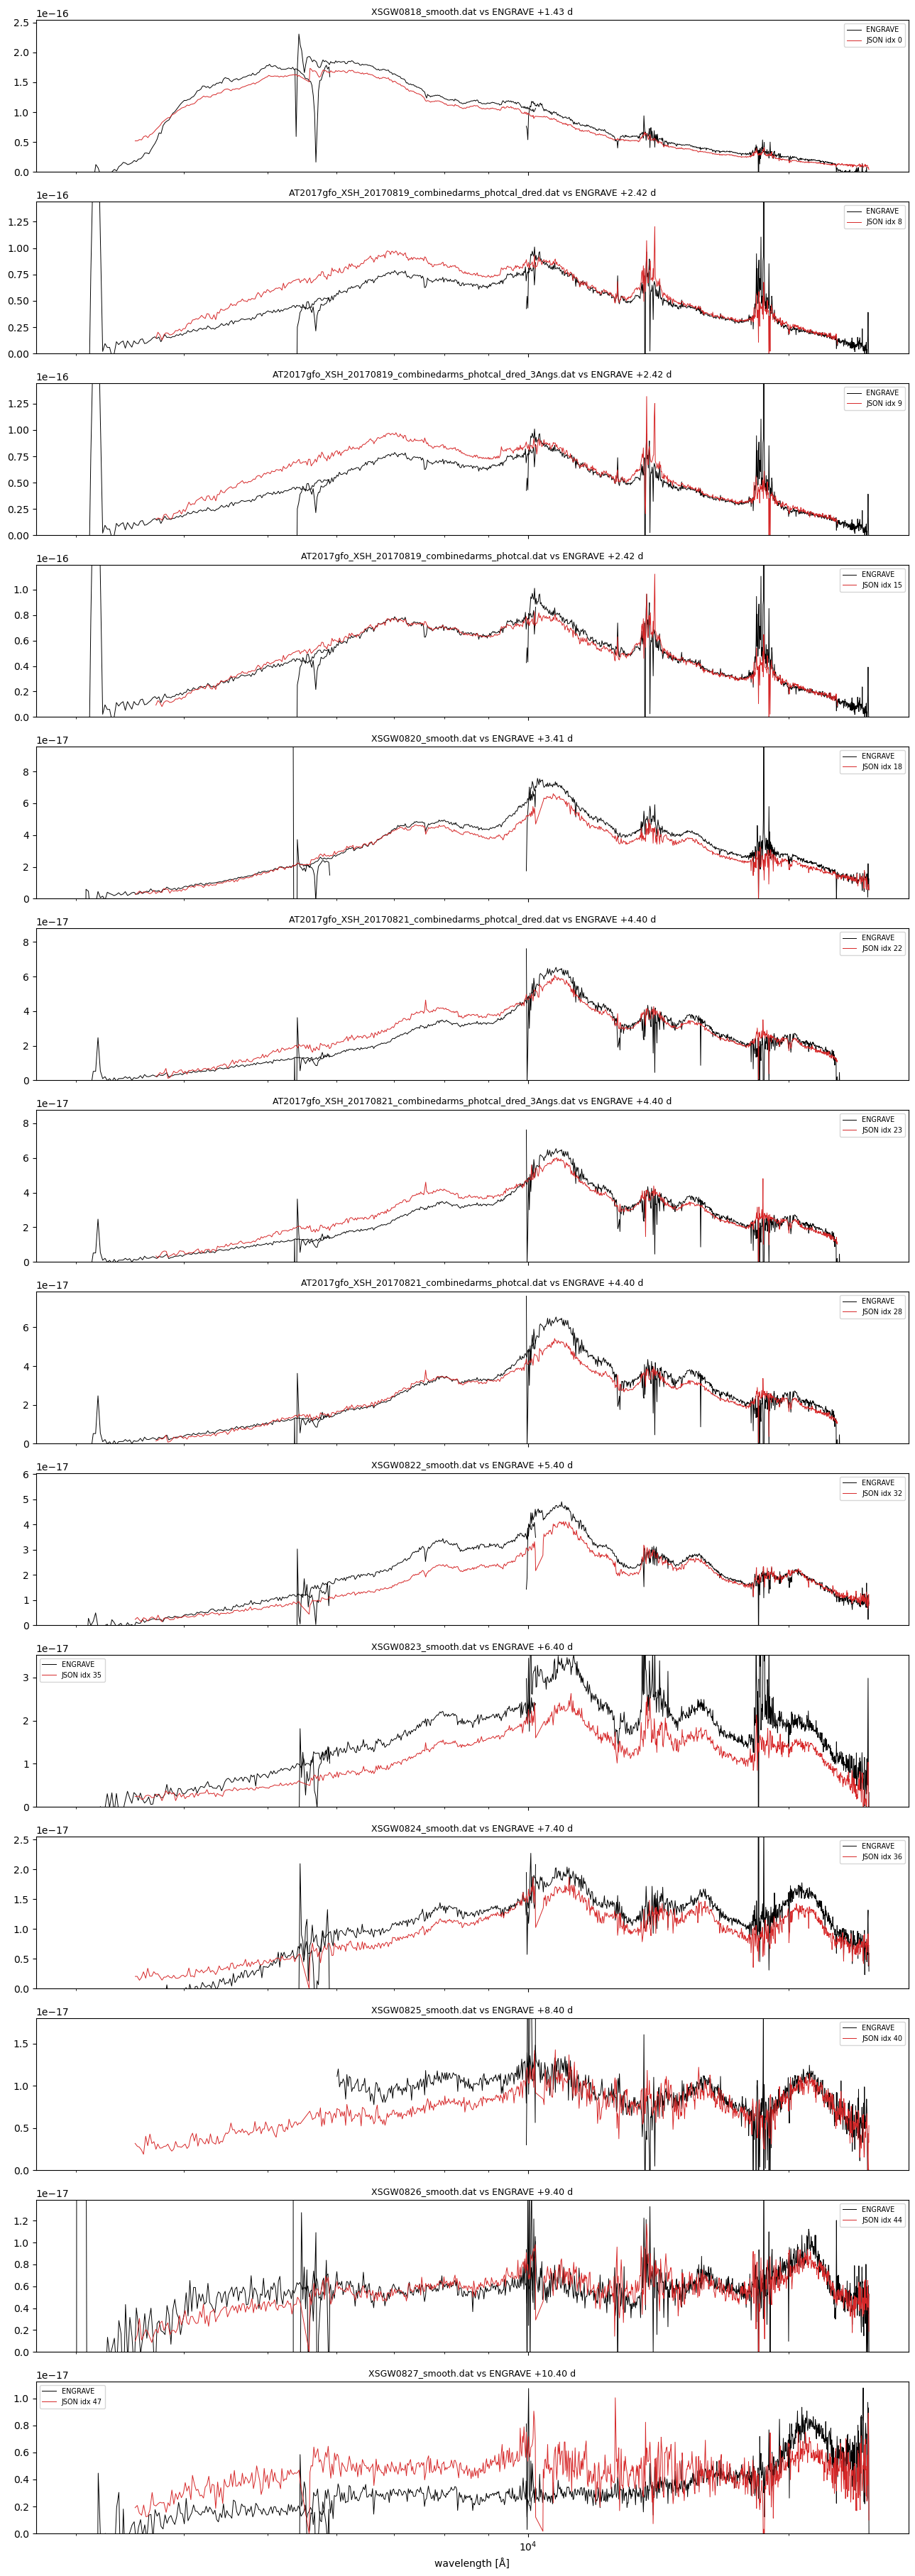

In [6]:
fig, axs = plt.subplots(len(xsh_cmp), 1, figsize=(13, 2.6 * len(xsh_cmp)), sharex=True)
def binned(w, f, step=20.0):
    e = np.arange(w.min(), w.max() + step, step); i = np.digitize(w, e)
    k = np.unique(i)
    return np.array([w[i == j].mean() for j in k]), np.array([np.median(f[i == j]) for j in k])
for ax, (_, r) in zip(axs, xsh_cmp.iterrows()):
    for arm, d in eng[r.engrave_phase].items():
        x, y = binned(d[:, 0], d[:, 1]); ax.plot(x, y, color="k", lw=0.7, label="ENGRAVE" if arm == "VIS" else None)
    w, f = si.spectrum_array(ev["spectra"][r.idx]); x, y = binned(w, f)
    ax.plot(x, y, color="tab:red", lw=0.7, label="JSON idx %d" % r.idx)
    ax.set_xscale("log"); ax.set_ylim(0, np.nanpercentile(y, 99) * 1.5)
    ax.set_title("%s vs ENGRAVE +%.2f d" % (r.json_file, r.engrave_phase), fontsize=9); ax.legend(fontsize=7)
axs[-1].set_xlabel("wavelength [Å]")
plt.tight_layout()

## 4. Dereddened copies

`AT2017gfo_XSH_20170819/0821_combinedarms_photcal_dred*.dat` (catalog sources Smartt+2017 and WISeREP) divided by the same file without `_dred` follows the Milky Way extinction curve, CCM89 with E(B-V) = 0.1053 and R_V = 3.1, to about 1%. These copies have Galactic dust removed, so they must not be fed to the pipeline, which fits spectra **as observed**.

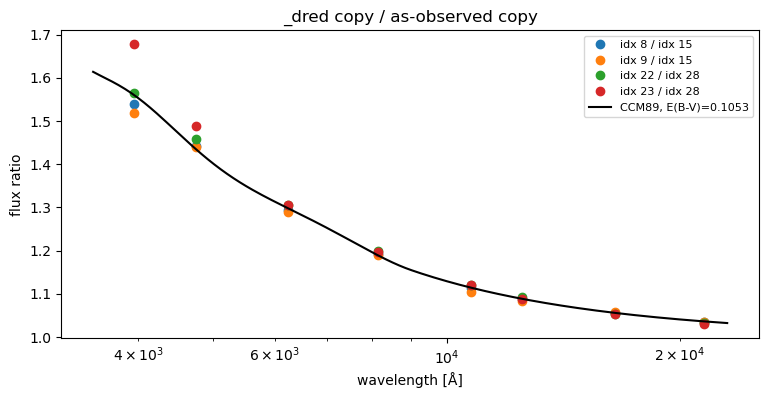

In [7]:
bands = [(3700, 4200), (4500, 5000), (6000, 6500), (7800, 8500), (10500, 11000), (12000, 13000),
         (16000, 17000), (21000, 22000)]
centres = np.array([0.5 * (a + b) for a, b in bands])
fig, ax = plt.subplots(figsize=(9, 4))
for dred, obs in [(8, 15), (9, 15), (22, 28), (23, 28)]:
    w1, f1 = si.spectrum_array(ev["spectra"][dred]); w2, f2 = si.spectrum_array(ev["spectra"][obs])
    ax.plot(centres, si.band_ratios(w1, f1, w2, f2, bands), "o", label="idx %d / idx %d" % (dred, obs))
g = np.geomspace(3500, 23000, 200)
ax.plot(g, si.mw_extinction_factor(g, EBV_MW), "k-", label="CCM89, E(B-V)=%.4f" % EBV_MW)
ax.set_xscale("log"); ax.set_xlabel("wavelength [Å]"); ax.set_ylabel("flux ratio"); ax.legend(fontsize=8)
ax.set_title("_dred copy / as-observed copy");

## 5. Same data, different flux scale

A search over all pairs for spectra whose shapes agree to better than 0.005 dex finds one pair: Pian's `SSS17a_GS_v1_2.5d.dat` (Gemini-S GMOS, catalog time 57984.0) and Kasliwal's `GW170817_GMOS_20170820.dat` (catalog time 57985.0) are **the same pixels, with flux different by a factor 0.316**. Only one should be used, and its flux scale has to come from the photometry (step 5 mangling will do that, but the two disagree by a factor of 3).

In [8]:
pairs = si.same_data_pairs(ev)
pairs["file_i"] = [ev["spectra"][i]["filename"] for i in pairs.i]
pairs["file_j"] = [ev["spectra"][j]["filename"] for j in pairs.j]
pairs

,i,j,scatter_dex,scale,file_i,file_j
0,10,17,1.110353e-07,0.316266,SSS17a_GS_v1_2.5d.dat,GW170817_GMOS_20170820.dat


## 6. Frame and telluric test

For each spectrum: the mean fractional depth of the O$_2$ A band (7594-7640 Å) at its **observed** position and at its position if the spectrum had been **de-redshifted** (divided by 1+z). A dip at the rest position means the spectrum is in the rest frame. Calibration: the ENGRAVE spectra (observed frame) never show a rest-position dip above 0.012; the Shappee LDSS3/MagE spectra show 0.03-0.28. The plots show the region for every optical spectrum: dashed = observed O$_2$ A band, dotted = where it falls in a rest-frame spectrum.

- **Rest frame:** all Shappee LDSS3/MagE, and Nicholl's IMACS spectrum at 57990.98 (check by eye below; it is the only Nicholl spectrum flagged).
- **Tellurics not removed:** the GMOS spectra (Pian and Kasliwal) and Pian's FORS2 (40-50% A-band dip).
- NIR-only spectra (FLAMINGOS-2, SOFI) cannot be tested this way; assume observed frame.

In [9]:
inv[["idx", "instrument", "paper", "O2A_obs", "O2A_rest", "frame"]]

,idx,instrument,paper,O2A_obs,O2A_rest,frame
0,0,VLT-UT2 - X-Shooter,"Pian+2017 (Nature 551, 67); WISeREP",0.012,-0.001,no clear O2 signal (corrected?)
1,1,LDSS3,"Shappee+2017 (Science 358, 1574)",-0.009,0.040,rest frame (O2 dip at λ/(1+z))
2,2,LDSS3,"Shappee+2017 (Science 358, 1574)",NaN,NaN,no O2 coverage
3,3,LDSS3,"Shappee+2017 (Science 358, 1574)",-0.000,0.051,rest frame (O2 dip at λ/(1+z))
4,4,LDSS3,"Shappee+2017 (Science 358, 1574)",NaN,NaN,no clear O2 signal (corrected?) (B band only)
5,5,EFOSC2,"Smartt+2017 (Nature 551, 75)",-0.003,-0.014,no clear O2 signal (corrected?)
6,6,Goodman Spectro,"Nicholl+2017 (ApJL 848, L18)",0.034,0.003,"observed, telluric residuals"
7,7,LDSS3,"Shappee+2017 (Science 358, 1574)",-0.012,0.034,rest frame (O2 dip at λ/(1+z))
8,8,VLT-UT2 - X-Shooter,"Smartt+2017 (Nature 551, 75); WISeREP",-0.025,0.001,no clear O2 signal (corrected?)
9,9,VLT-UT2 - X-Shooter,"Smartt+2017 (Nature 551, 75); WISeREP",-0.016,0.000,no clear O2 signal (corrected?)


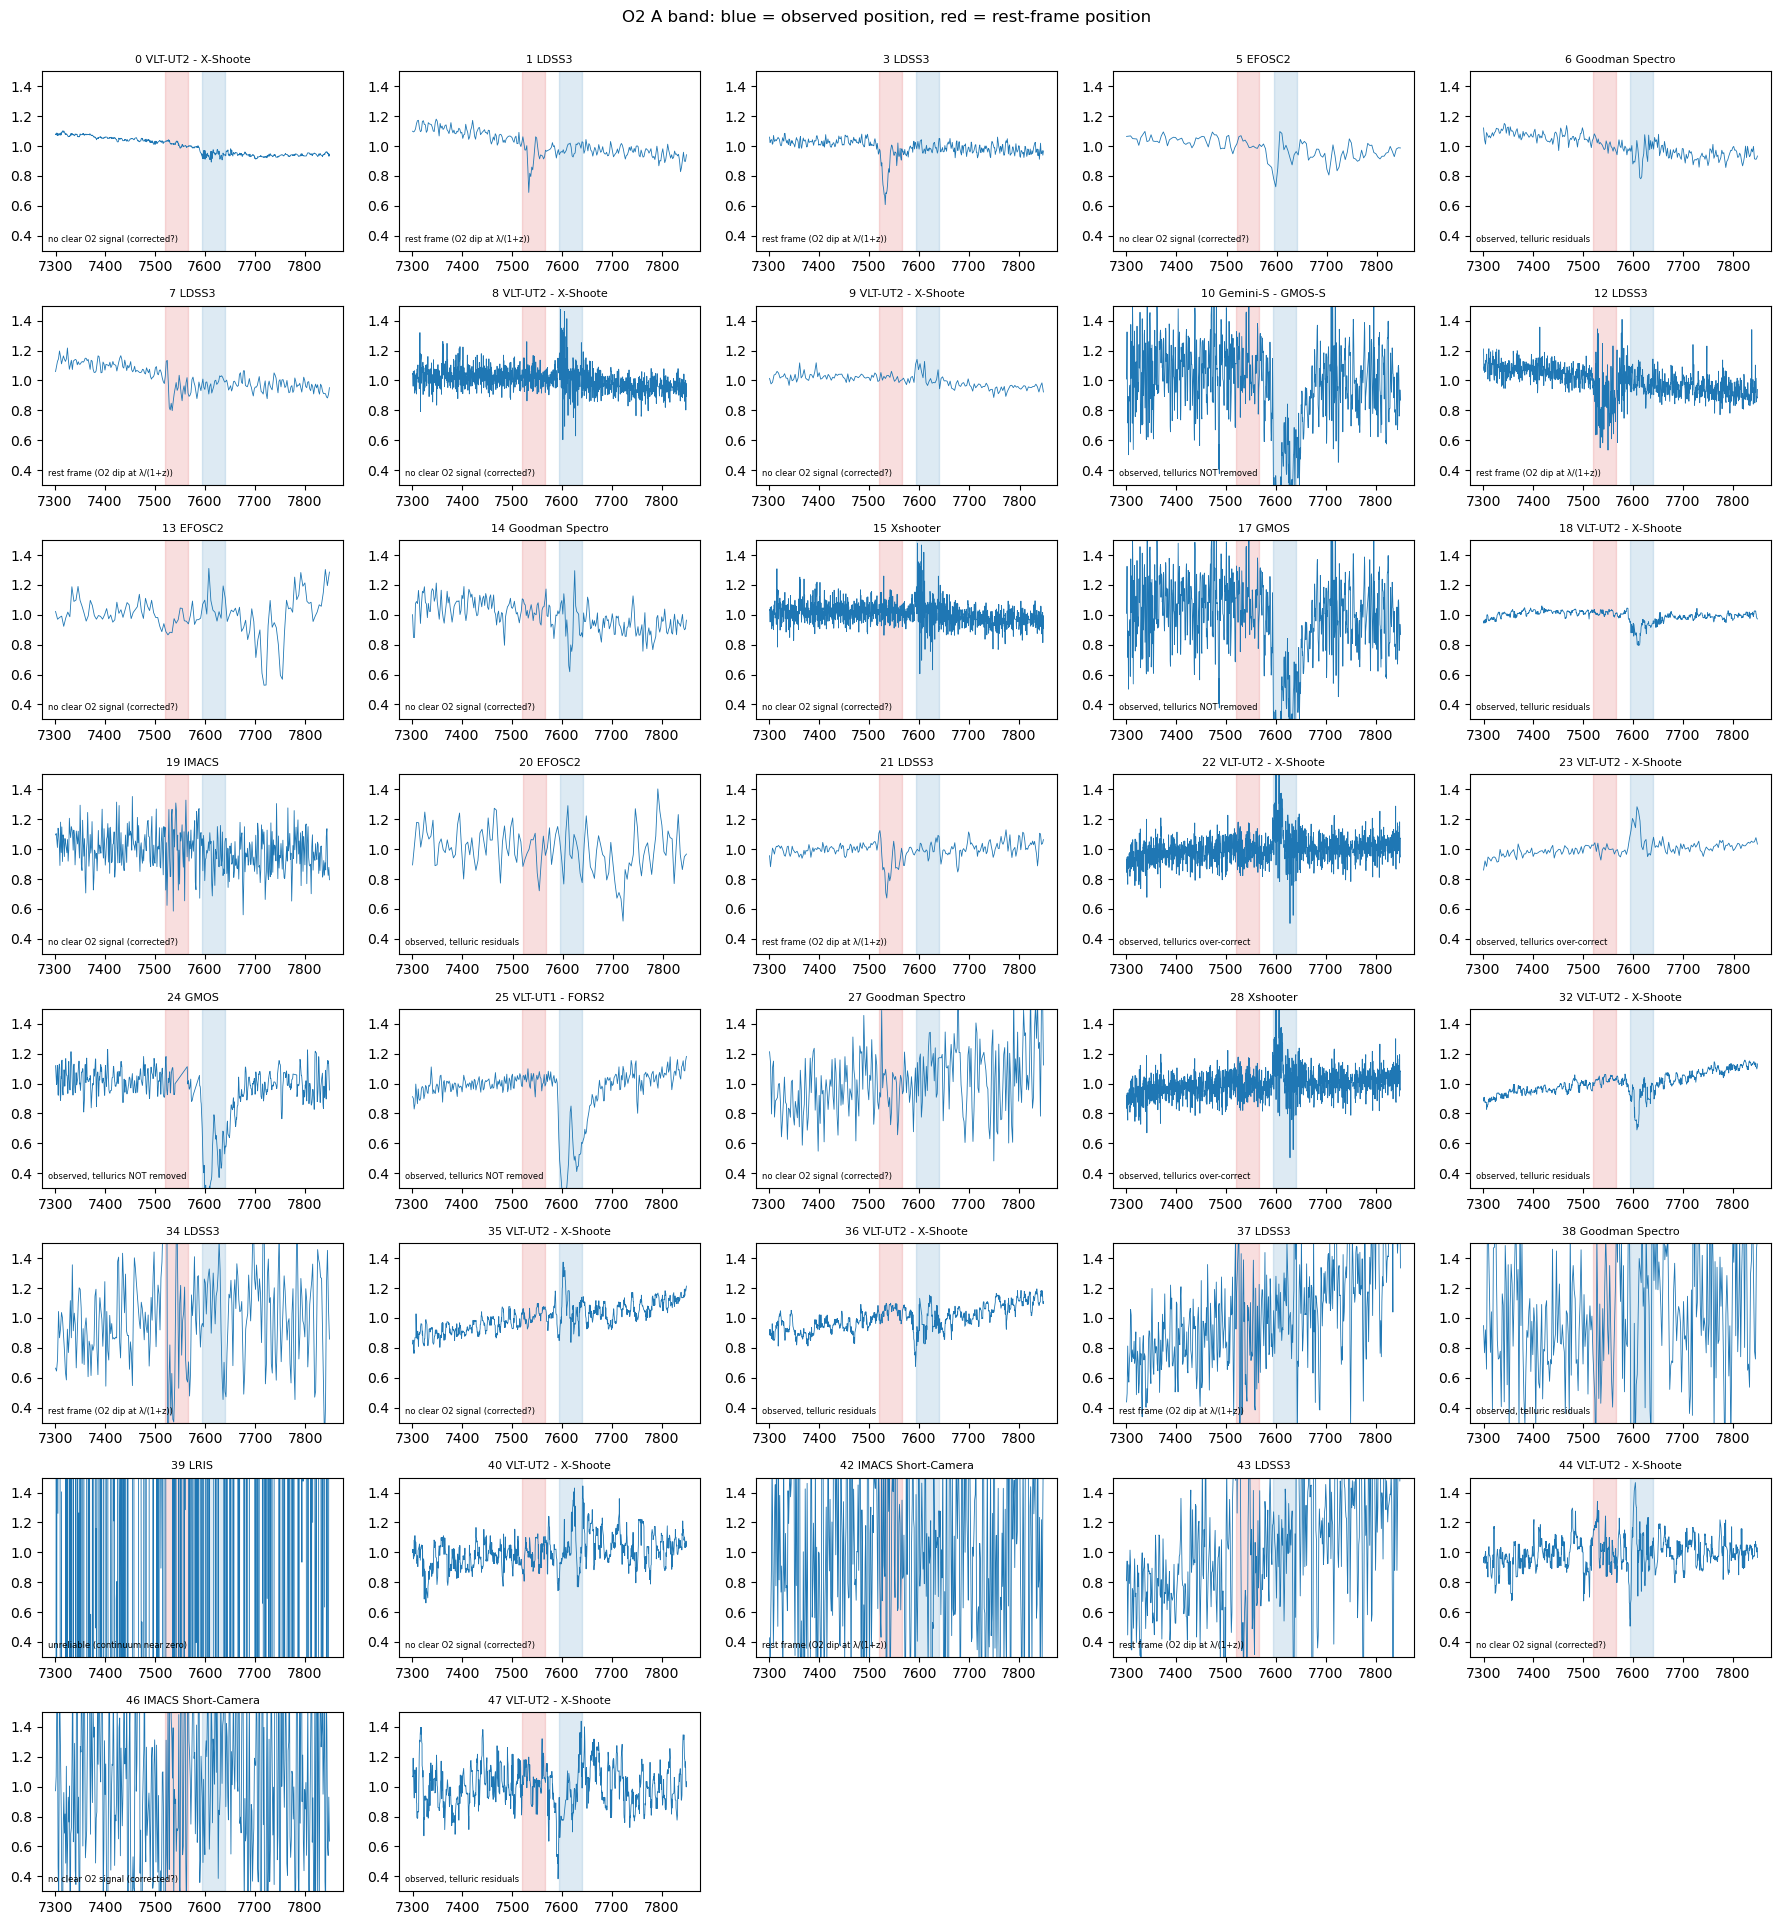

In [10]:
opt = inv[(inv.wl_min < 7400) & (inv.wl_max > 7800)]
n = len(opt); ncol = 5; nrow = int(np.ceil(n / ncol))
fig, axs = plt.subplots(nrow, ncol, figsize=(18, 2.4 * nrow))
for ax, (_, r) in zip(axs.ravel(), opt.iterrows()):
    w, f = si.spectrum_array(ev["spectra"][r.idx]); s = (w > 7300) & (w < 7850)
    ax.plot(w[s], f[s] / np.nanmedian(f[s]), lw=0.6)
    ax.axvspan(7594, 7640, color="tab:blue", alpha=0.15); ax.axvspan(7594 / (1 + Z), 7640 / (1 + Z), color="tab:red", alpha=0.15)
    ax.set_ylim(0.3, 1.5); ax.set_title("%d %s" % (r.idx, r.instrument[:18]), fontsize=8)
    ax.text(0.02, 0.05, r.frame[:32], transform=ax.transAxes, fontsize=6)
for ax in axs.ravel()[n:]:
    ax.axis("off")
fig.suptitle("O2 A band: blue = observed position, red = rest-frame position", y=1.0)
plt.tight_layout()

## 7. The new spectra

Everything the JSON has that we do not use, grouped by instrument, with the ENGRAVE spectrum at the nearest epoch for reference (both binned to 20 Å). The ratio table gives new / ENGRAVE in overlapping bands, as a first look at how different each group's flux calibration is (ENGRAVE at a different time by up to ~0.5 d, so part of the ratio is real evolution).

In [11]:
NEW_BANDS = {"B 4400-5400": (4400, 5400), "R 6000-7000": (6000, 7000), "I 7700-8800": (7700, 8800),
             "J 11500-13000": (11500, 13000), "H 15500-17500": (15500, 17500), "K 20500-22500": (20500, 22500)}
new = inv[inv.status.str.startswith("NEW") | inv.status.str.startswith("same data as Kasliwal")]
rows = []
for _, r in new.iterrows():
    ph_new = r.mjd_probable - T0
    ph = eng_phases[np.argmin(np.abs(eng_phases - ph_new))]
    w, f = si.spectrum_array(ev["spectra"][r.idx])
    if "rest frame" in r.frame:
        w = w * (1 + Z)
    rat = {}
    for name, (lo, hi) in NEW_BANDS.items():
        arm = "UVB" if hi <= 5400 else "VIS" if hi <= 9500 else "NIR"
        if arm in eng[ph] and w.min() < lo and w.max() > hi:
            d = eng[ph][arm]; rat[name] = round(si.band_ratios(w, f, d[:, 0], d[:, 1], [(lo, hi)])[0], 3)
        else:
            rat[name] = np.nan
    rows.append(dict(idx=r.idx, phase_d=round(ph_new, 2), instrument=r.instrument, paper=r.paper.split(";")[0],
                     wl="%.0f-%.0f" % (r.wl_min, r.wl_max), engrave_phase=ph, **rat))
new_cmp = pd.DataFrame(rows)
new_cmp

,idx,phase_d,instrument,paper,wl,engrave_phase,B 4400-5400,R 6000-7000,I 7700-8800,J 11500-13000,H 15500-17500,K 20500-22500
0,5,1.44,EFOSC2,"Smartt+2017 (Nature 551, 75)",3332-9974,1.43,0.959,1.023,1.104,NaN,NaN,NaN
1,6,1.45,Goodman Spectro,"Nicholl+2017 (ApJL 848, L18)",4000-8035,1.43,1.024,1.040,NaN,NaN,NaN,NaN
2,10,2.50,Gemini-S - GMOS-S,"Pian+2017 (Nature 551, 67)",5600-9200,2.42,NaN,0.402,0.394,NaN,NaN,NaN
3,11,1.50,FLAMINGOS2,"Chornock+2017 (ApJL 848, L19)",9071-18001,1.43,NaN,NaN,NaN,0.828,0.745,NaN
4,13,2.45,EFOSC2,"Smartt+2017 (Nature 551, 75)",3331-9972,2.42,1.148,1.117,1.140,NaN,NaN,NaN
5,14,2.45,Goodman Spectro,"Nicholl+2017 (ApJL 848, L18)",4000-8036,2.42,0.911,1.271,NaN,NaN,NaN,NaN
6,16,2.46,FLAMINGOS2,"Chornock+2017 (ApJL 848, L19)",9074-18008,2.42,NaN,NaN,NaN,1.265,1.270,NaN
7,17,2.47,GMOS,"Kasliwal+2017 (Science 358, 1559)",5600-9200,2.42,NaN,1.270,1.246,NaN,NaN,NaN
8,19,2.49,IMACS,"Shappee+2017 (Science 358, 1574)",4408-8665,2.42,NaN,1.597,NaN,NaN,NaN,NaN
9,20,3.44,EFOSC2,"Smartt+2017 (Nature 551, 75)",3333-9985,3.41,1.152,1.120,0.926,NaN,NaN,NaN


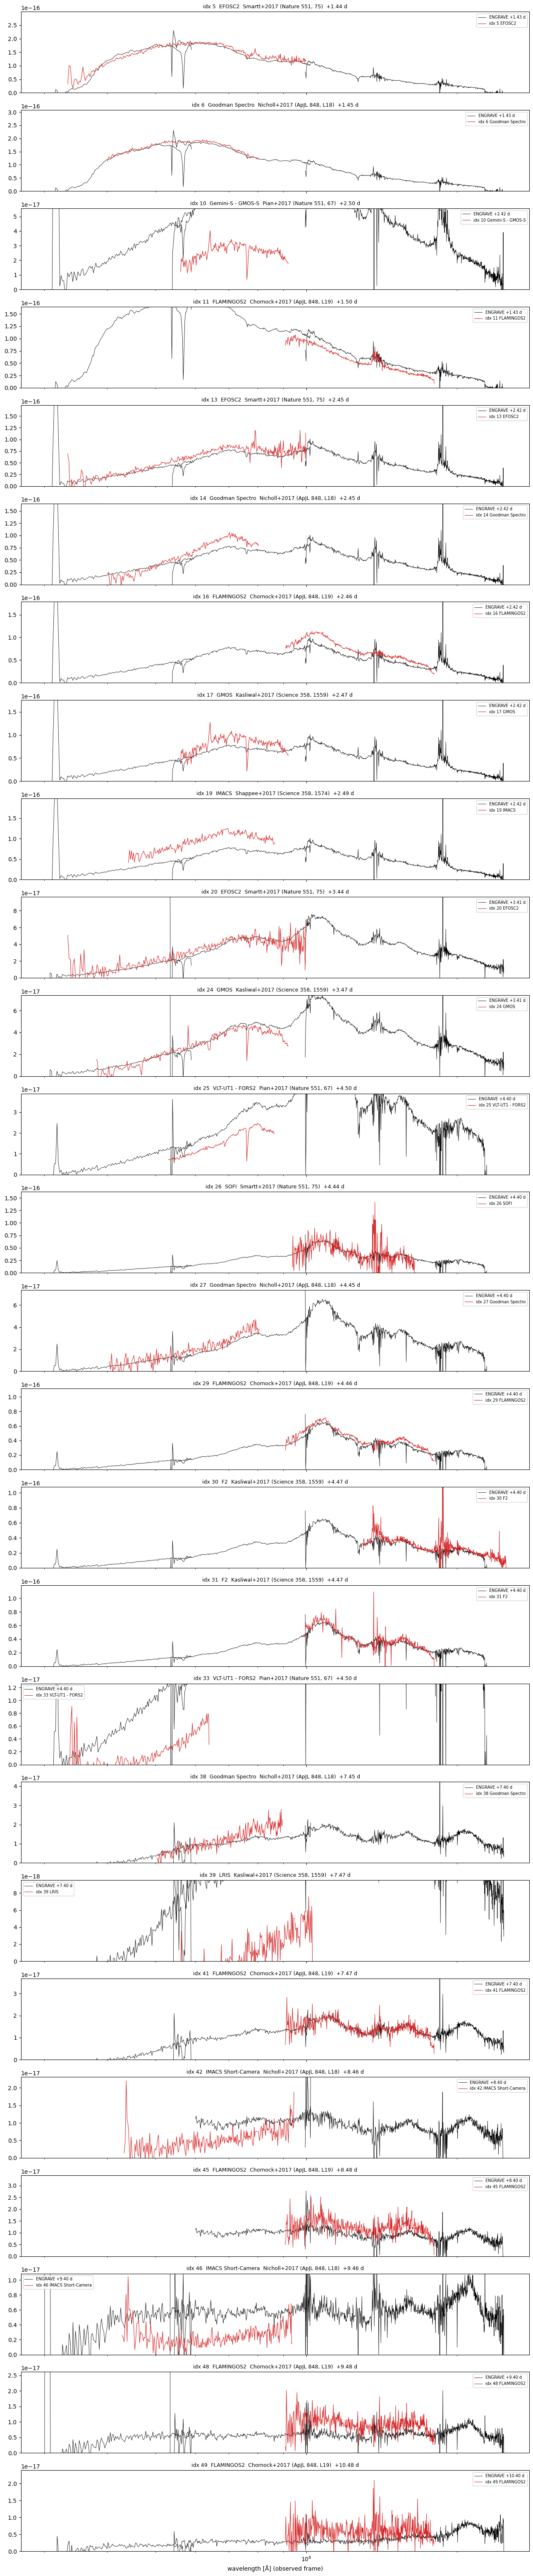

In [12]:
fig, axs = plt.subplots(len(new_cmp), 1, figsize=(13, 2.4 * len(new_cmp)), sharex=True)
for ax, (_, r) in zip(axs, new_cmp.iterrows()):
    for arm, d in eng[r.engrave_phase].items():
        x, y = binned(d[:, 0], d[:, 1]); ax.plot(x, y, color="k", lw=0.6, label="ENGRAVE +%.2f d" % r.engrave_phase if arm == "VIS" else None)
    w, f = si.spectrum_array(ev["spectra"][r.idx])
    if "rest frame" in inv.loc[r.idx, "frame"]:
        w = w * (1 + Z)
    x, y = binned(w, f); ax.plot(x, y, color="tab:red", lw=0.8, label="idx %d %s" % (r.idx, r.instrument))
    ax.set_xscale("log"); ax.set_ylim(0, np.nanpercentile(y, 99) * 1.6)
    ax.set_title("idx %d  %s  %s  +%.2f d" % (r.idx, r.instrument, r.paper, r.phase_d), fontsize=9); ax.legend(fontsize=7)
axs[-1].set_xlabel("wavelength [Å] (observed frame)")
plt.tight_layout()

## 8. Literature: published spectra not in the JSON

From a web search of the papers, WISeREP (object 9596, 43 spectra), kilonova.org and the Sneppen GitHub repository (November 2026). **Nothing was downloaded.** Bibcodes for Pian, Smartt and Kasliwal were confirmed on WISeREP; the others should be checked on ADS. The ENGRAVE release page could not be opened (certificate error). MJDs marked ≈ were converted from UT dates.

**Published, not in the JSON:**

| Paper | Telescope / instrument | Epochs | λ range | Notes | Where |
|---|---|---|---|---|---|
| McCully+2017 (ApJL 848, L32); same data in Buckley+2018 (MNRAS 474, L71) and Andreoni+2017 | SALT RSS | 57983.714 (+1.18 d), 57984.707 (+2.16 d) | 3600-8000 Å | Relative flux only; twilight; absorption depth depends on the standard star (Sneppen+2024) | Not on WISeREP. Raw data: SAAO archive (2017-1-DDT-009). Re-reduced +1.17 d: github.com/Sneppen/Kilonova-analysis |
| McCully+2017 | LCO FTS FLOYDS | 57984.359 (+1.81 d) | 5500-9250 Å | Flux warped to gri photometry | Not found |
| Andreoni+2017 (PASA 34, e069) | ANU 2.3 m WiFeS | 4 nights, ≈57983.39 to 57986.40 (+0.86 to +3.87 d) | 3300-9800 Å | Earliest after Magellan; some tellurics poorly removed; calibration not described | Not found |
| Andreoni+2017 | AAT 2dF/AAOmega | ≈57989.37 (+6.9 d) | 3750-8900 Å | Host-subtracted; "indicative" | Not found |
| Tanvir+2017 (ApJL 848, L27) | VLT MUSE | +1.47 d | 4800-9300 Å | Scaled to photometry, not dereddened | ESO archive raw data (inferred) |
| Tanvir+2017 / Troja+2017 | HST WFC3/IR G102 | +4.86, +7.27, +10.52 d | 0.80-1.15 µm | No tellurics; host removed with a 2-D fit; scaled to photometry | MAST raw (GO 14771, 14804); no released reductions found |
| Tanvir+2017 / Troja+2017 | HST WFC3/IR G141 | +4.93, +9.43, +10.65 d | 1.08-1.70 µm | Spurious ~1.4 µm feature at +4.9 and +9.4 d (Gillanders+2023) | MAST raw |
| Nicholl+2017 | HST STIS NUV G230L | +5.5 d | 1600-3200 Å | S/N < 1: effectively an upper limit (≲1.5e-18 at 2500 Å) | MAST (15382); maybe kilonova.org |
| Smartt+2017 / PESSTO SSDR4 | NTT EFOSC2 (second frames, red grism, inferred) | ≈57984.01, 57985.02, 57986.02 | red optical | About 1 h after the EFOSC2 spectra in the JSON | WISeREP 71550, 71552, 71554; ESO Phase 3 |
| Sneppen+2023 | X-shooter sub-epoch splits | within +1.4 d | UVB-NIR | Same data as ENGRAVE, split in time | github.com/Sneppen/Kilonova-analysis |

**Not new or not usable:** Covino+2017 / Bulla+2019 FORS2 polarimetry (no flux spectrum found); Kasliwal FLAMINGOS-2 HK on Aug 29 (no detection); Watson+2019 and Gillanders+2022/23 reuse X-shooter data. No spectra later than +10.65 d were found.

**Duplicates across papers:** the Gemini GMOS spectra at 57985.04 and 57986.01 are the same observations in McCully, Kasliwal and Troja (Troja's program, shared), and the same SALT data appear in McCully, Buckley and Andreoni.

**Notes from the papers that matter here (secondhand, via the search):**
- Kasliwal's "Gemini-South LRIS" spectrum is **Keck I LRIS**, 2017-08-25 05:45 UT ≈ MJD 57990.24 (+7.71 d), at airmass 3.8-6, host-contaminated.
- Nicholl+2017 scaled the SOAR/IMACS spectra to DECam photometry and corrected them for Milky Way extinction and redshift; the slit was on the host nucleus (host absorption near 5100 and 7100 Å). In this notebook the O$_2$ test finds observed-frame residuals in two Goodman spectra and a rest-frame dip in the IMACS spectrum at +8.46 d, so treat the frame of each Nicholl spectrum as unverified.
- Gillanders+2022 describe the ENGRAVE release as calibrated to photometry, extinction-corrected and in the rest frame. **The ENGRAVE per-arm files used here do not look like that:** their O$_2$ telluric residuals sit at the observed wavelengths at all 10 epochs (section 6), and their colour matches Smartt's non-dereddened X-shooter reduction to about 10% while Smartt's dereddened copy is 29% bluer in B/I (cell below). The release may contain several products; check its notes when the page is reachable.

In [13]:
# Is ENGRAVE dereddened? Colour (B/I flux ratio) of other reductions relative to ENGRAVE.
# Milky Way dereddening would make a spectrum bluer than an as-observed one by this factor:
B_BAND, I_BAND = (4500, 5300), (7800, 8600)
ccm = si.mw_extinction_factor([4900], EBV_MW)[0] / si.mw_extinction_factor([8200], EBV_MW)[0]
def eng_all(ph):
    parts = [eng[ph][k] for k in ("UVB", "VIS", "NIR") if k in eng[ph]]
    w = np.concatenate([p[:, 0] for p in parts]); f = np.concatenate([p[:, 1] for p in parts]); o = np.argsort(w)
    return w[o], f[o]
rows = []
for idx, ph, label in [(15, 2.42, "Smartt X-shooter, as observed"), (28, 4.40, "Smartt X-shooter, as observed"),
                       (8, 2.42, "Smartt X-shooter, _dred"), (22, 4.40, "Smartt X-shooter, _dred"),
                       (0, 1.43, "Pian X-shooter"), (18, 3.41, "Pian X-shooter")]:
    w, f = si.spectrum_array(ev["spectra"][idx]); we, fe = eng_all(ph)
    rb, ri = si.band_ratios(w, f, we, fe, [B_BAND, I_BAND])
    rows.append(dict(idx=idx, version=label, engrave_phase=ph, B_ratio=round(rb, 3), I_ratio=round(ri, 3),
                     colour_vs_ENGRAVE=round(rb / ri, 3)))
print("MW dereddening changes B/I by x%.3f (CCM89, E(B-V)=%.4f)" % (ccm, EBV_MW))
print("If ENGRAVE were dereddened, the as-observed Smartt copies would show ~%.2f; the _dred copies ~1.0." % (1 / ccm))
pd.DataFrame(rows)

MW dereddening changes B/I by x1.191 (CCM89, E(B-V)=0.1053)
If ENGRAVE were dereddened, the as-observed Smartt copies would show ~0.84; the _dred copies ~1.0.


,idx,version,engrave_phase,B_ratio,I_ratio,colour_vs_ENGRAVE
0,15,"Smartt X-shooter, as observed",2.42,1.082,0.994,1.089
1,28,"Smartt X-shooter, as observed",4.40,0.930,0.998,0.931
2,8,"Smartt X-shooter, _dred",2.42,1.529,1.190,1.285
3,22,"Smartt X-shooter, _dred",4.40,1.363,1.201,1.134
4,0,Pian X-shooter,1.43,0.903,0.928,0.973
5,18,Pian X-shooter,3.41,0.957,0.910,1.051


## 9. Summary

**What the JSON adds.** Of its 50 spectra, 10 are the Magellan spectra we already use (identical), 10 are other reductions of the X-shooter nights we take from ENGRAVE, 4 are dereddened copies, and 1 is a rescaled duplicate. That leaves **25 new spectra from 7 instruments**:

| Instrument (paper) | n | Phases (d) | λ (Å) | Before use |
|---|---|---|---|---|
| NTT EFOSC2 (Smartt+2017) | 3 | 1.44, 2.45, 3.44 | 3330-9980 | Calibrated to photometry; small telluric residuals |
| NTT SOFI (Smartt+2017) | 1 | 4.44 | 9380-16470 | NIR; frame not testable |
| SOAR Goodman (Nicholl+2017) | 4 | 1.45, 2.45, 4.45, 7.45 | 4000-8970 | Paper says scaled, dereddened, de-redshifted: verify each |
| Magellan IMACS (Shappee+2017) | 1 | 2.49 | 4410-8670 | Shappee's other spectra are rest frame; this one shows no clear O$_2$ signal |
| Magellan IMACS (Nicholl+2017) | 2 | 8.46, 9.46 | 4280-9360 | +8.46 d shows a rest-frame dip |
| Gemini-S GMOS (Kasliwal+2017; same data as Pian, McCully, Troja) | 2 | 2.47, 3.47 | 3800-9200 | **Tellurics not removed**; Pian's copy of 2.47 d is 3.2× brighter |
| Gemini-S FLAMINGOS-2 (Chornock+2017) | 7 | 1.50-10.48 | 9070-18010 | NIR, daily; the main new NIR coverage |
| Gemini-S FLAMINGOS-2 JH + HK (Kasliwal+2017) | 2 | 4.47 | 9840-25070 | NIR |
| Keck I LRIS (Kasliwal+2017; JSON says Gemini-South) | 1 | ≈7.71 (JSON MJD 57990.0) | 5600-10300 | Airmass 3.8-6, host contaminated; JSON time is wrong |
| VLT FORS2 (Pian+2017) | 2 | ≈4.5 | 3330-8630 | **Not flux calibrated**, tellurics not removed |

**Published but not in the JSON** (section 8): SALT RSS (+1.18, +2.16 d), LCO FLOYDS (+1.81 d), ANU WiFeS (4 nights from +0.86 d), AAT (+6.9 d), VLT MUSE (+1.47 d), six HST WFC3/IR grism spectra (+4.9 to +10.65 d), one HST STIS UV spectrum (+5.5 d, essentially a non-detection) and three extra EFOSC2 frames (WISeREP). Most have no public reduced spectrum; the EFOSC2 frames (WISeREP), the Sneppen SALT re-reduction (GitHub) and the HST raw data (MAST) are the reachable ones.

**Differences between the JSON and published versions.**
- Magellan: identical to our files; both are in the rest frame, and two of our "LDSS3" files are MagE.
- X-shooter: Pian's smoothed reduction agrees with ENGRAVE to ~10% at +1.4 and +3.4 d but differs in level and colour later; Smartt's as-observed reduction agrees with ENGRAVE to a few percent at +2.4 d and within 10-15% at +4.4 d.
- JSON timestamps are rounded to the day for Pian, Kasliwal and Smartt's dereddened copies (up to ~1 d early); use the night in the file name.
- Every JSON spectrum lacks flux errors: notebook 0.3 would estimate them.
- The JSON spectra that are not ours have **not** yet been compared with their WISeREP or kilonova.org versions, because that needs downloading those files.

**Before adding any of these to the pipeline:**
1. Choose one version per observation (drop the `_dred` copies, Pian's GMOS duplicate, and the older X-shooter reductions).
2. Put every spectrum in the observed frame (add rest-frame ones to `REST_FRAME_FILES`) and make sure none is dereddened.
3. Skip or heavily clip FORS2 and GMOS tellurics; fix the LRIS time.
4. Run them through notebooks 0.2 and 0.3, then step 4 → 3 → 5 → 6.